# Group 20 — Part D: Advanced models, results and conclusion
**Task:** predict taxi trip duration (minutes) at pickup — regression.
**Input:** Member B's feature matrices (built on Member A's cleaned NYC TLC Yellow Taxi data).
**Scoring:** Member C's shared `evaluate()` and scoreboard, so every number is comparable with C's baselines.

| Setting | Meaning |
|---|---|
| `ETA_B_RUN` | folder with B's `features_{train,validation,test}.parquet` |
| `ETA_C_RUN` | folder with C's `C_scoreboard.csv` for the **same** data |
| `ETA_THREADS` | threads per model (fixed, recorded) |
| `ETA_RUN` | output folder under `outputs/` |

On Rockhill: `bash run_rockhill_d.sh` (uses the `cs4207` partition).

In [1]:
import os, sys, json, time, platform, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
warnings.filterwarnings('ignore', category=UserWarning)

B_DIR = Path(os.environ.get('ETA_B_DIR', '../Group20_ETA_B'))
C_DIR = Path(os.environ.get('ETA_C_DIR', '../Group20_ETA_C'))
B_RUN = B_DIR / 'outputs' / os.environ.get('ETA_B_RUN', 'local_sample')
C_RUN = C_DIR / 'outputs' / os.environ.get('ETA_C_RUN', 'local_sample')
RUN = os.environ.get('ETA_RUN', 'local_sample')
OUT = Path('outputs') / RUN; FIG = OUT / 'figures'; FIG.mkdir(parents=True, exist_ok=True)

sys.path[:0] = ['.', str(C_DIR)]
import d_models as dm, d_figures as dfig
from c_models import evaluate, to_minutes, Scoreboard          # C's shared scoring
THREADS = dm.threads()
T_START = time.perf_counter()

import sklearn, lightgbm, xgboost
summary = {'run': RUN, 'features_from': str(B_RUN), 'baselines_from': str(C_RUN),
           'environment': {'host': platform.node(), 'platform': platform.platform(), 'python': platform.python_version(),
                           'cpus_visible': os.cpu_count(), 'slurm_cpus': os.environ.get('SLURM_CPUS_PER_TASK'),
                           'threads_per_model': THREADS, 'gpu': 'not used',
                           'pandas': pd.__version__, 'numpy': np.__version__, 'scikit-learn': sklearn.__version__,
                           'lightgbm': lightgbm.__version__, 'xgboost': xgboost.__version__},
           'config': {'seed': dm.SEED, 'grids': dm.GRIDS, 'rf_trees': dm.RF_TREES, 'rf_max_samples': dm.RF_MAX_SAMPLES,
                      'boost_max_rounds': dm.BOOST_ROUNDS, 'early_stopping_rounds': dm.EARLY_STOP,
                      'learning_rate': dm.LEARNING_RATE, 'not_features': dm.NOT_FEATURES, 'categorical': dm.CATEGORICAL}}
def save(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=180, bbox_inches='tight'); plt.close(fig); display(Image(FIG / f'{name}.png'))
summary['environment']

{'host': 'vm',
 'platform': 'Linux-6.18.44-fc-v880-x86_64-with-glibc2.39',
 'python': '3.13.18',
 'cpus_visible': 2,
 'slurm_cpus': None,
 'threads_per_model': 2,
 'gpu': 'not used',
 'pandas': '3.0.5',
 'numpy': '2.5.3',
 'scikit-learn': '1.9.1',
 'lightgbm': '4.7.0',
 'xgboost': '3.4.1'}

## 1. Data and inputs
B's features only use information available at pickup (no distance, fare, tip, payment or dropoff time).
D additionally drops `day_of_month`: training covers days 1–21 and test covers 27–31, so a tree would treat every test day as day 21.
B's zone codes come from a fixed vocabulary, so the boosters use them as **categorical** features.

In [2]:
data = dm.load_features(B_RUN)
X_example, _ = dm.split_xy(data['train'])
summary['rows'] = {s: len(data[s]) for s in dm.SPLITS}
summary['n_features'] = X_example.shape[1]
summary['features'] = list(X_example.columns)
print({s: f"{len(data[s]):,} trips, {data[s].pickup_datetime.min():%d %b} to {data[s].pickup_datetime.max():%d %b}" for s in dm.SPLITS})
print(f'{X_example.shape[1]} model inputs; dropped:', list(dm.NOT_FEATURES))

{'train': '67,074 trips, 01 Jan to 21 Jan', 'validation': '14,415 trips, 22 Jan to 26 Jan', 'test': '18,511 trips, 27 Jan to 31 Jan'}
32 model inputs; dropped: ['duration_minutes', 'pickup_datetime', 'day_of_month']


## 2. Hyperparameter tuning on validation
Each model is trained on `log1p(duration)` (right-skewed target). For every grid point we fit on **train** and score on **validation** (MAE in minutes).
The boosters use early stopping on the validation loss; the test period is not touched until section 3.

In [3]:
trials, chosen = [], {}
for name in ['Random Forest', 'LightGBM', 'XGBoost']:
    t0 = time.perf_counter()
    table, chosen[name] = dm.tune(name, data, evaluate, to_minutes, THREADS)
    trials.append(table)
    print(f'{name}: {len(table)} configurations in {time.perf_counter() - t0:.0f} s; best {chosen[name]["params"]}')
trials = pd.concat(trials, ignore_index=True)
trials.to_csv(OUT / 'd_tuning_trials.csv', index=False)
summary['tuning'] = trials.round(4).to_dict('records')
trials.round(3)

Random Forest: 4 configurations in 43 s; best {'min_samples_leaf': 5, 'max_features': 0.6}


LightGBM: 4 configurations in 11 s; best {'num_leaves': 127, 'min_child_samples': 100}


XGBoost: 4 configurations in 18 s; best {'max_depth': 6, 'min_child_weight': 20}


,model,min_samples_leaf,max_features,rounds,fit_s,MAE,RMSE,R2,bias,num_leaves,min_child_samples,max_depth,min_child_weight
0,Random Forest,5.0,0.33,300,8.55,4.150,7.258,0.663,-1.362,NaN,NaN,NaN,NaN
1,Random Forest,5.0,0.60,300,14.47,4.130,7.197,0.669,-1.334,NaN,NaN,NaN,NaN
2,Random Forest,20.0,0.33,300,6.72,4.267,7.524,0.638,-1.474,NaN,NaN,NaN,NaN
3,Random Forest,20.0,0.60,300,11.75,4.234,7.430,0.647,-1.417,NaN,NaN,NaN,NaN
4,LightGBM,NaN,NaN,617,2.33,3.907,6.666,0.716,-1.087,31.0,20.0,NaN,NaN
5,LightGBM,NaN,NaN,563,2.36,3.900,6.657,0.716,-1.087,31.0,100.0,NaN,NaN
6,LightGBM,NaN,NaN,206,2.27,3.904,6.631,0.719,-1.091,127.0,20.0,NaN,NaN
7,LightGBM,NaN,NaN,283,3.27,3.891,6.600,0.721,-1.078,127.0,100.0,NaN,NaN
8,XGBoost,NaN,NaN,316,2.54,3.941,6.722,0.711,-1.147,NaN,NaN,6.0,1.0
9,XGBoost,NaN,NaN,380,2.91,3.926,6.701,0.713,-1.153,NaN,NaN,6.0,20.0


## 3. Chosen models on validation and test
Each chosen configuration is scored once on test. The rows are added to **C's scoreboard for the same data**, so baselines, linear models and tree models share one table.

In [4]:
board = Scoreboard.load(C_RUN / 'C_scoreboard.csv')
c_n = {r['split']: r['n'] for r in board.rows}
assert c_n['validation'] == len(data['validation']) and c_n['test'] == len(data['test']), 'C scoreboard is from different data'
preds = {}
for name, ch in chosen.items():
    M = dm.matrices(data, ch['categorical'])
    for split in ('validation', 'test'):
        X, y = M[split]
        p = dm.predict_minutes(ch['model'], X, to_minutes)
        preds[(name, split)] = p
        board.add(name, split, y, p, owner='D', group='advanced')
board.save(OUT / 'scoreboard_all.csv')
table = board.table()
best = table.loc[list(chosen), 'validation_MAE'].idxmin()          # chosen on VALIDATION
summary['scoreboard'] = table.round(4).reset_index().to_dict('records')
summary['best_model'] = {'name': best, 'params': chosen[best]['params'],
                         **{k: float(v) for k, v in table.loc[best].items()}}
table.round(2)

,validation_MAE,validation_RMSE,validation_R2,validation_bias,test_MAE,test_RMSE,test_R2,test_bias
model,,,,,,,,
Constant (train median),8.04,12.83,-0.05,-2.89,10.50,16.78,-0.20,-6.83
Constant (train mean),8.66,12.52,-0.00,0.70,10.19,15.67,-0.04,-3.24
Same weekday & hour,8.02,12.75,-0.04,-2.78,10.39,16.57,-0.17,-6.59
Zone-pair median,4.91,8.95,0.49,-1.59,7.76,12.93,0.29,-5.52
Linear: calendar features only,7.05,11.52,0.15,-2.06,9.35,15.07,0.03,-5.67
Linear: + zone encodings,4.78,8.57,0.53,-1.49,7.32,12.21,0.37,-5.08
Ridge: + zone encodings,4.78,8.57,0.53,-1.50,7.32,12.21,0.37,-5.09
Tuned linear: + interactions,4.57,8.11,0.58,-1.24,7.05,11.57,0.43,-4.78
Random Forest,4.13,7.20,0.67,-1.33,6.77,11.02,0.48,-5.04


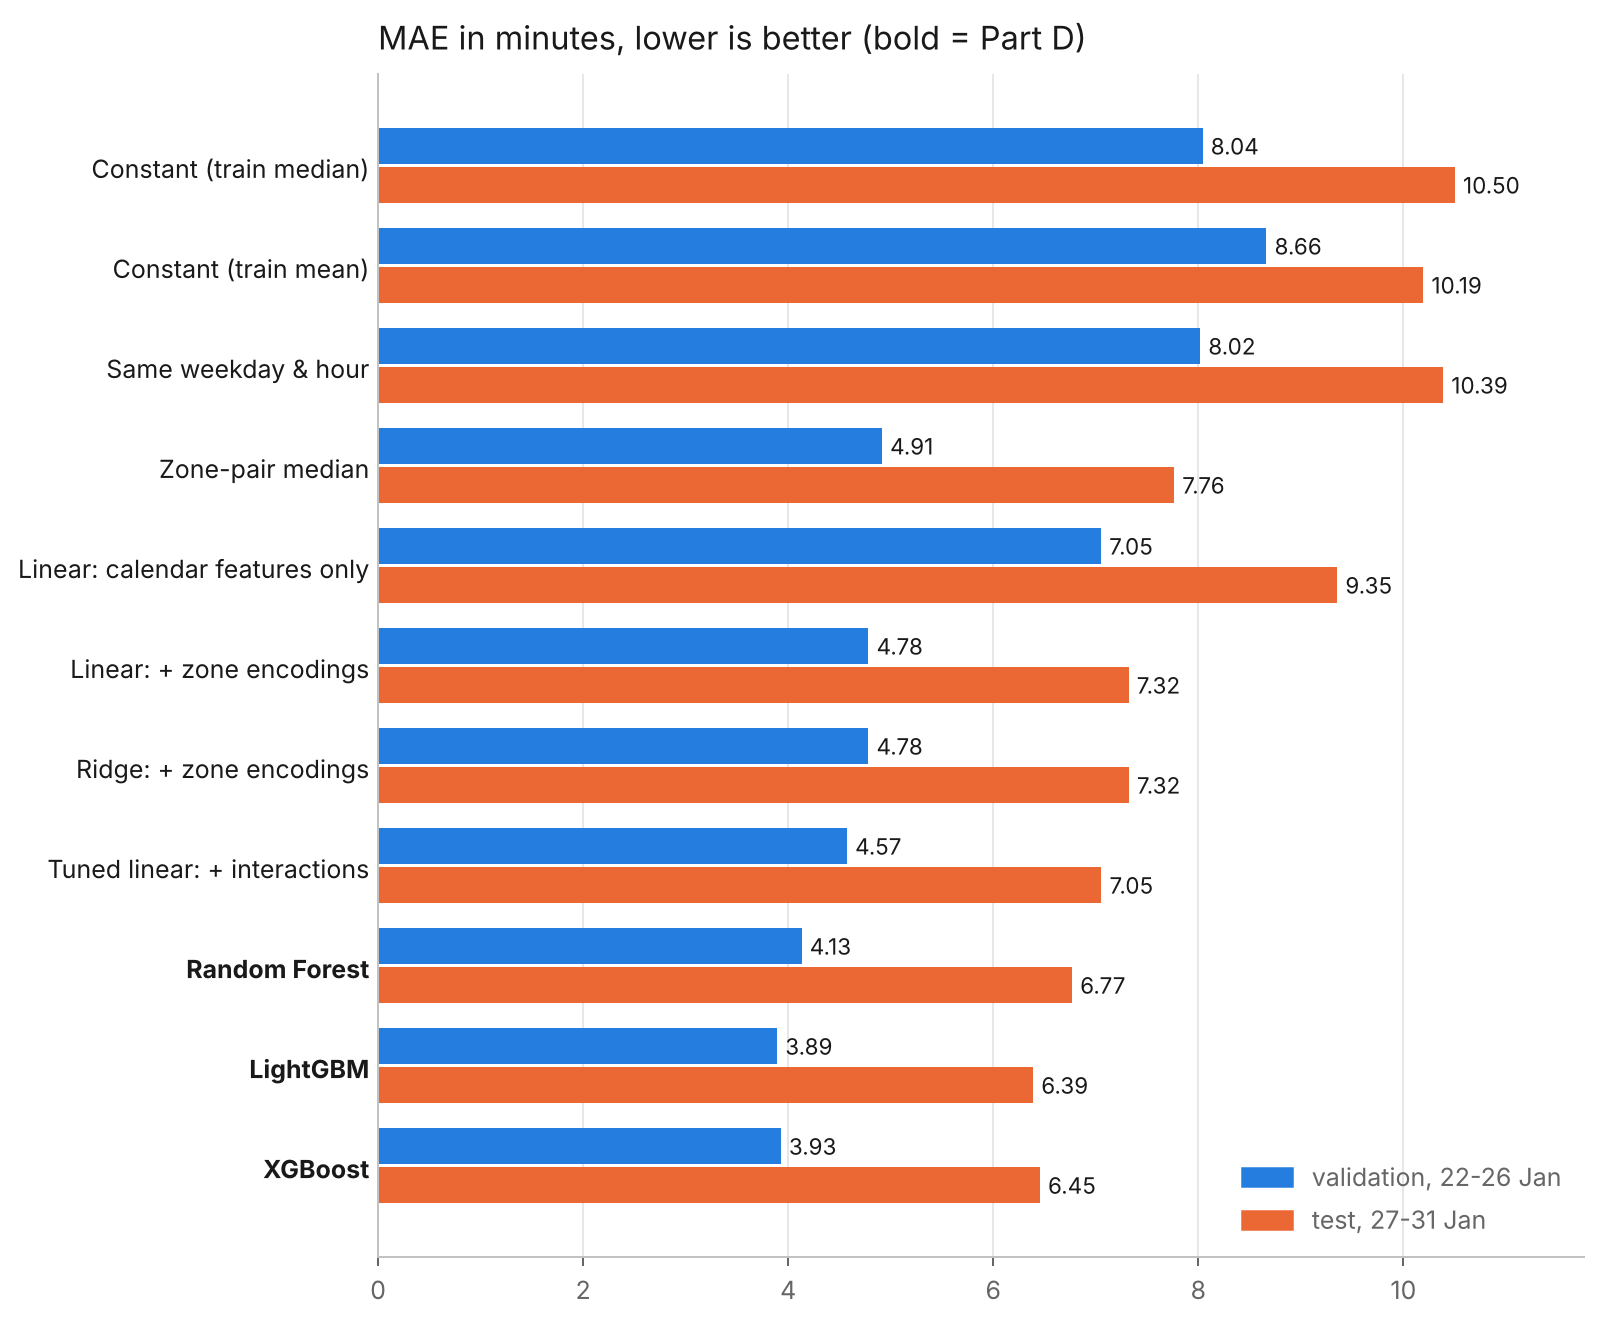

{'validation_vs_constant_pct': np.float64(51.6),
 'test_vs_constant_pct': np.float64(39.2),
 'validation_vs_zone_pair_pct': np.float64(20.8),
 'test_vs_zone_pair_pct': np.float64(17.7),
 'validation_vs_best_linear_pct': np.float64(14.9),
 'test_vs_best_linear_pct': np.float64(9.4)}

In [5]:
fig = dfig.model_comparison(table, highlight=list(chosen))
save(fig, 'D_model_comparison')
lin = [m for m in table.index if m not in chosen and not m.startswith(('Constant', 'Same', 'Zone'))]
ref = {'constant': 'Constant (train median)', 'zone_pair': 'Zone-pair median',
       'best_linear': table.loc[lin, 'validation_MAE'].idxmin()}
gain = {}
for k, m in ref.items():
    for s in ('validation', 'test'):
        gain[f'{s}_vs_{k}_pct'] = round(100 * (1 - table.loc[best, f'{s}_MAE'] / table.loc[m, f'{s}_MAE']), 1)
summary['reference_models'] = ref; summary['improvement'] = gain
gain

## 4. What the best model uses
Gain importance: the share of the total loss reduction from splits on each feature.

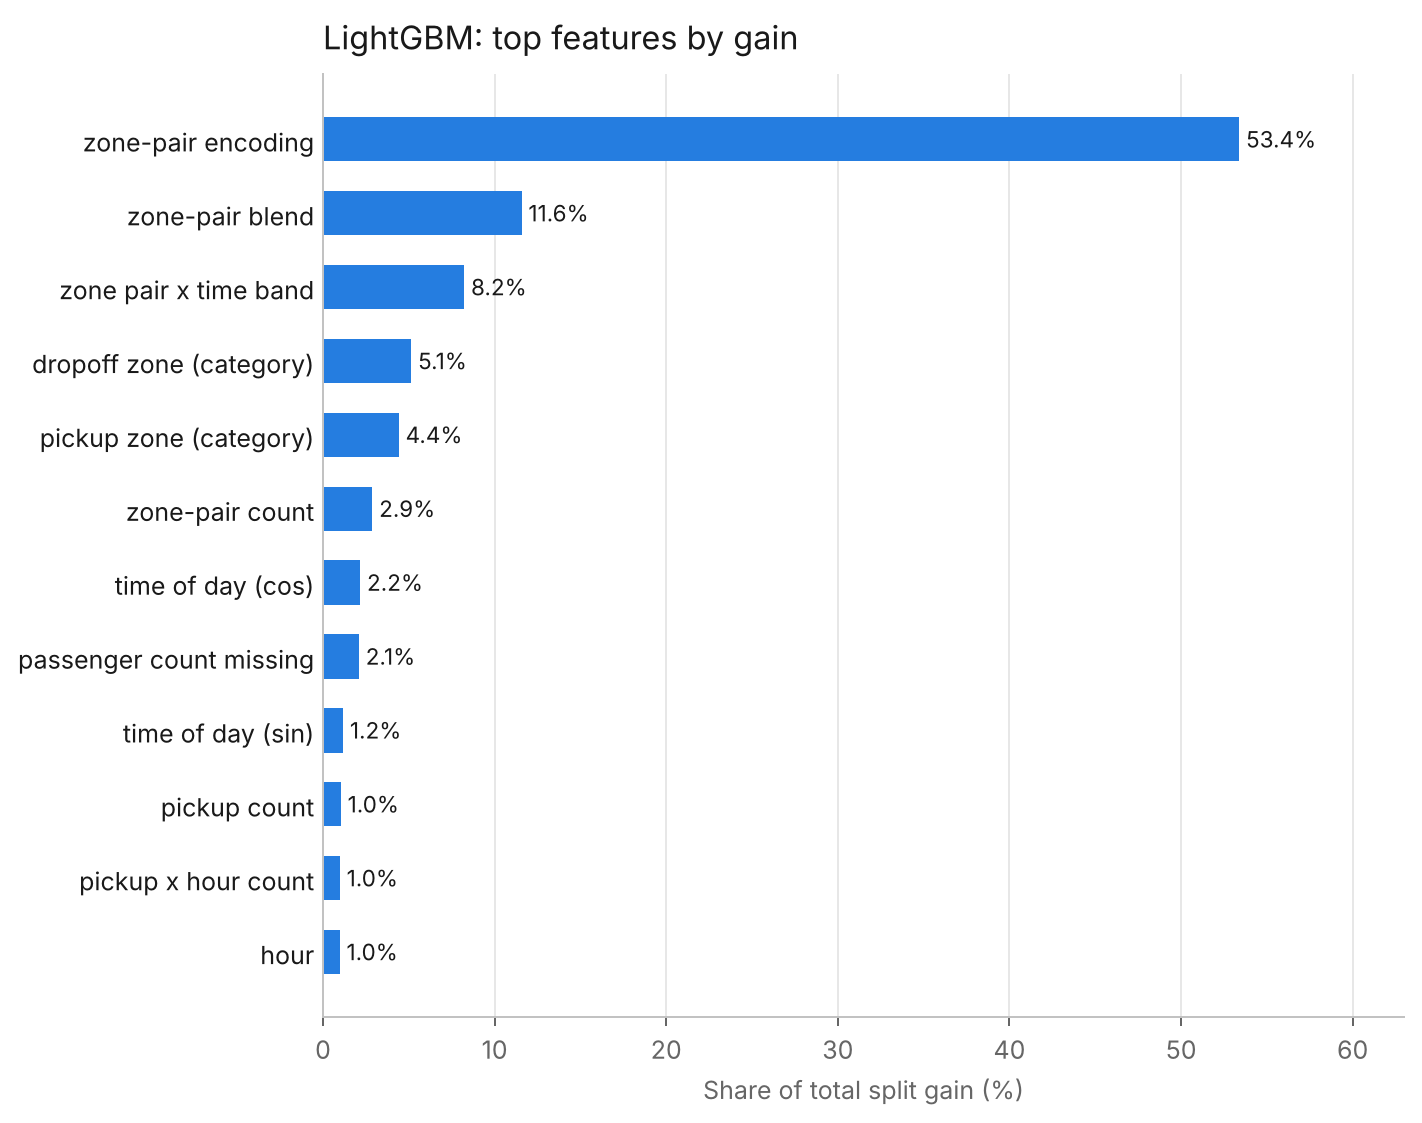

Location-based features (zone encodings, zone codes, airport/same-zone flags): 91.4% of total gain


In [6]:
X_cols = dm.matrices(data, chosen[best]['categorical'])['train'][0].columns
imp = dm.importance(best, chosen[best]['model'], X_cols)
imp.to_csv(OUT / 'd_feature_importance.csv', header=['gain_share'])
save(dfig.feature_importance(imp, f'{best}: top features by gain'), 'D_feature_importance')
zone = imp[[c for c in imp.index if c.startswith('te_') or 'zone' in c or 'airport' in c]].sum()
summary['importance_top'] = imp.head(8).round(4).to_dict()
summary['importance_location_share'] = round(float(zone), 3)
print(f'Location-based features (zone encodings, zone codes, airport/same-zone flags): {100*zone:.1f}% of total gain')

## 5. Errors: predicted vs actual, trip length and day

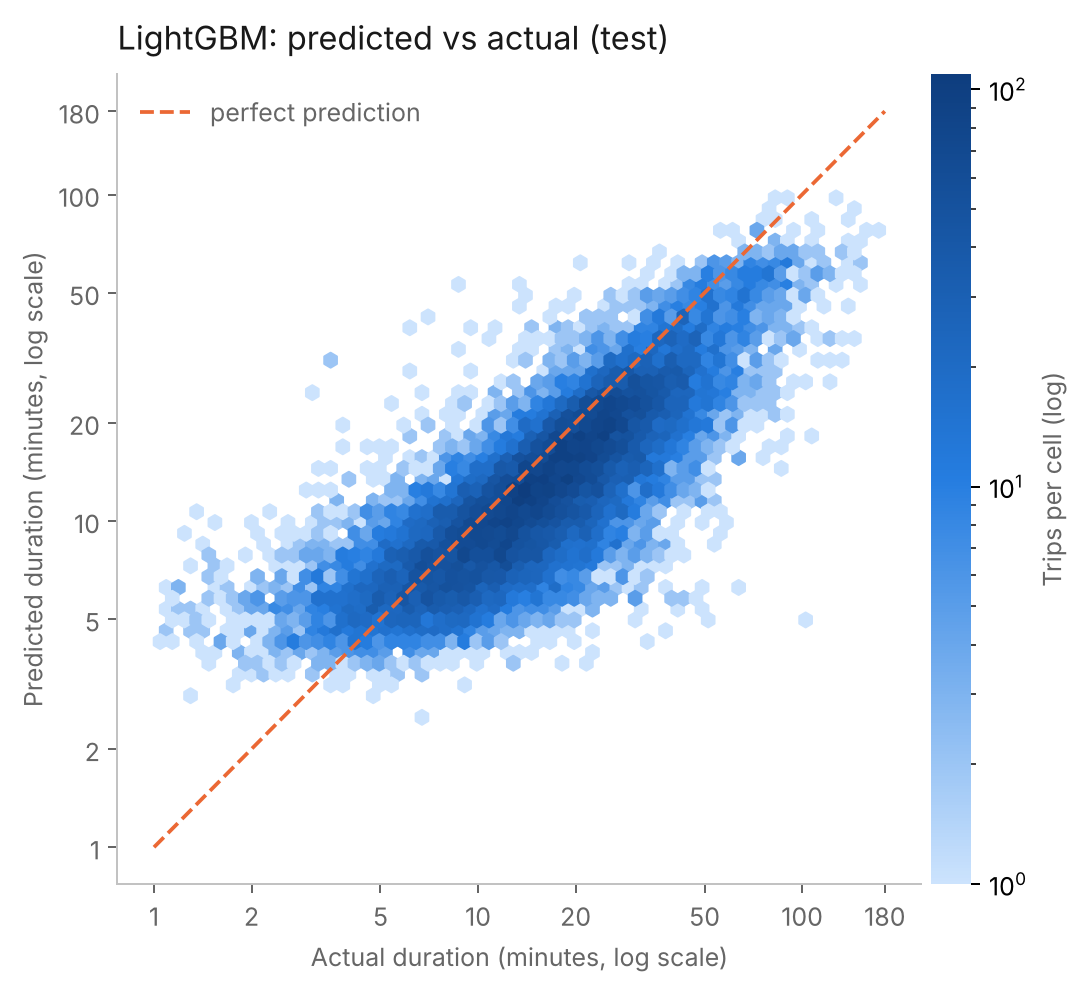

,trips,MAE,bias
bucket,,,
"(-0.001, 5.0]",1093,2.45,2.40
"(5.0, 10.0]",3720,1.97,0.27
"(10.0, 20.0]",6796,3.89,-2.44
"(20.0, 40.0]",5304,8.67,-7.62
"(40.0, 180.0]",1598,22.44,-21.66


{'2026-01-22': 4.44,
 '2026-01-23': 4.11,
 '2026-01-24': 3.33,
 '2026-01-25': 3.56,
 '2026-01-26': 3.78,
 '2026-01-27': 7.11,
 '2026-01-28': 7.29,
 '2026-01-29': 7.2,
 '2026-01-30': 6.45,
 '2026-01-31': 4.2}

In [7]:
y_te = data['test']['duration_minutes'].to_numpy(); p_te = preds[(best, 'test')]
save(dfig.predicted_vs_actual(y_te, p_te, f'{best}: predicted vs actual (test)'), 'D_pred_vs_actual')
buckets = dm.error_by_bucket(y_te, p_te)
summary['test_error_by_duration'] = buckets.reset_index().to_dict('records')
daily = {}
for split in ('validation', 'test'):
    d = data[split].assign(p=preds[(best, split)])
    for day, g in d.groupby(d.pickup_datetime.dt.date):
        daily[str(day)] = round(float(np.abs(g.p - g.duration_minutes).mean()), 2)
summary['daily_MAE_best'] = daily
display(buckets); daily

## 6. Non-determinism in the tree models
**Found in Part D:** with a fixed seed, two refits of the Random Forest gave test predictions that differed in the last digits.
Training is reproducible (each tree has its own seed), but `predict()` adds the 300 tree outputs from several threads
**in whatever order the threads finish**. Floating-point addition is not associative, so the sum changes from call to call.
**Fix:** predict with one thread (fixed summation order); training stays multi-threaded.

In [8]:
rf = chosen['Random Forest']['model']
X_rf = dm.matrices(data, False)['test'][0]
rf.set_params(n_jobs=THREADS)
order = dm.prediction_order_experiment(rf, X_rf, to_minutes, repeats=4)
summary['nondeterminism_rf_prediction'] = order.to_dict('records')
order

,prediction,calls,distinct_outputs,fingerprints,max_abs_diff_min
0,parallel (threads finish in any order),4,4,e501de3b9160 0f6e682787b7 9a5556860692 ba5e66c...,1.065814e-13
1,fixed order (1 prediction thread),4,1,913ecf218b36 913ecf218b36 913ecf218b36 913ecf2...,0.000000e+00


**Reproducibility check** for every chosen model: refit twice with the fixed seed, once with a single thread, and twice with `seed=None`.
With the fix, the fixed-seed fingerprints must be identical. `seed=None` shows how much the seed matters
(scikit-learn then draws a fresh seed each time; LightGBM and XGBoost fall back to their own default seed).

In [9]:
repro = {}
for name in chosen:
    r = dm.reproducibility_check(name, chosen[name]['params'], data, to_minutes, THREADS)
    repro[name] = r.to_dict('records')
    print(name); display(r)
summary['reproducibility'] = repro

Random Forest


,run,threads,fingerprint,max_abs_diff_vs_run1_min
0,"seed fixed, run 1",2,913ecf218b36,0.000000
1,"seed fixed, run 2",2,913ecf218b36,0.000000
2,"seed fixed, 1 thread",1,913ecf218b36,0.000000
3,"seed=None, run 1",2,bbdec34456fa,5.457026
4,"seed=None, run 2",2,27cf6e3862e5,5.057977


LightGBM


,run,threads,fingerprint,max_abs_diff_vs_run1_min
0,"seed fixed, run 1",2,ec4230bc2d82,0.000000
1,"seed fixed, run 2",2,ec4230bc2d82,0.000000
2,"seed fixed, 1 thread",1,ec4230bc2d82,0.000000
3,"seed=None, run 1",2,276eb34c90f8,11.393069
4,"seed=None, run 2",2,276eb34c90f8,11.393069


XGBoost


,run,threads,fingerprint,max_abs_diff_vs_run1_min
0,"seed fixed, run 1",2,d99821bd1d47,0.000000
1,"seed fixed, run 2",2,d99821bd1d47,0.000000
2,"seed fixed, 1 thread",1,d99821bd1d47,0.000000
3,"seed=None, run 1",2,972c46667b3f,15.439774
4,"seed=None, run 2",2,972c46667b3f,15.439774


## 7. Summary of Part D

In [10]:
summary['runtime_s'] = round(time.perf_counter() - T_START, 1)
(OUT / 'd_summary.json').write_text(json.dumps(summary, indent=2, default=str))
b, g = summary['best_model'], summary['improvement']
r = repro[best]
same_seed = all(v[0]['fingerprint'] == v[1]['fingerprint'] == v[2]['fingerprint'] for v in repro.values())
o = summary['nondeterminism_rf_prediction']
display(Markdown(f"""
- **Best model (chosen on validation):** {best} {b['params']} — validation MAE **{b['validation_MAE']:.2f} min**, test MAE **{b['test_MAE']:.2f} min** (R² {b['validation_R2']:.2f} / {b['test_R2']:.2f}).
- **Against C:** {g['validation_vs_best_linear_pct']}% lower validation MAE than the best linear model, {g['validation_vs_zone_pair_pct']}% lower than the zone-pair baseline, {g['validation_vs_constant_pct']}% lower than a constant.
- **Location dominates:** {100*summary['importance_location_share']:.0f}% of the split gain comes from zone-based features.
- **Test is harder:** test bias {b['test_bias']:.2f} min — every model under-predicts after the 25 Jan snowstorm (daily MAE up to {max(v for k, v in summary['daily_MAE_best'].items() if k >= '2026-01-27'):.1f} min).
- **Non-determinism found:** Random Forest parallel prediction gave {o[0]['distinct_outputs']} different outputs in {o[0]['calls']} calls (up to {o[0]['max_abs_diff_min']:.1e} min); with one prediction thread {o[1]['distinct_outputs']} of {o[1]['calls']}.
- **Reproducible:** fixed seed → {'identical' if same_seed else 'DIFFERENT'} test predictions for all three models across reruns and thread counts.
- Run time {summary['runtime_s']:.0f} s on {THREADS} threads; outputs in `{OUT}`.
"""))


- **Best model (chosen on validation):** LightGBM {'num_leaves': 127, 'min_child_samples': 100} — validation MAE **3.89 min**, test MAE **6.39 min** (R² 0.72 / 0.54).
- **Against C:** 14.9% lower validation MAE than the best linear model, 20.8% lower than the zone-pair baseline, 51.6% lower than a constant.
- **Location dominates:** 91% of the split gain comes from zone-based features.
- **Test is harder:** test bias -4.75 min — every model under-predicts after the 25 Jan snowstorm (daily MAE up to 7.3 min).
- **Non-determinism found:** Random Forest parallel prediction gave 4 different outputs in 4 calls (up to 1.1e-13 min); with one prediction thread 1 of 4.
- **Reproducible:** fixed seed → identical test predictions for all three models across reruns and thread counts.
- Run time 206 s on 2 threads; outputs in `outputs/local_sample`.
